# 实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

**学号**：20244081112　**姓名**：杨俊堃　**课程**：Python数据处理A

本实验在独立 conda 虚拟环境 `exp01` 中完成（未使用 base 环境），按 `EXP02.pdf` 的四个实验依次实现：

1. NumPy 数组、数据类型与索引
2. 随机抽样、统计与缺失值
3. SciPy 数值计算与 Matplotlib 可视化
4. pandas Series、DataFrame 与内存中的 CSV 读写

所有涉及随机抽样的单元格都设置了**固定随机种子**，重复运行结果一致；图表直接在 Notebook 中显示，不保存为文件。

In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244081112
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp01
[学号]       20244081112
[机器指纹] 9c12af92e27612fd
[RUN_ID]   20244081112-9c12af92e27612fd


In [2]:
import matplotlib.pyplot as plt

print(f"NumPy      {np.__version__}")
print(f"SciPy      {scipy.__version__}")
print(f"Matplotlib {matplotlib.__version__}")
print(f"pandas     {pd.__version__}")

NumPy      2.0.2
SciPy      1.13.1
Matplotlib 3.9.4
pandas     2.3.3


## 实验1：NumPy 数组、数据类型与索引

### 1. 整数、浮点数与布尔值 ndarray

分别创建三种 `ndarray`，输出各自的 `dtype`、`shape` 和 `ndim`。

**NumPy 数组与 Python 列表的差别：**

| 方面 | `ndarray` | `list` |
|---|---|---|
| 元素类型 | 所有元素共用同一个 `dtype`（`int64` / `float64` / `bool`） | 可以混合任意对象 |
| 内存 | 连续的内存块，元素定长 | 存的是对象指针，元素分散在堆上 |
| 运算 | 支持整体向量化运算（`a + 1`、`a * 2`） | 需要循环或列表推导，`list * 2` 表示重复 |
| 维度 | 有 `shape`、`ndim`，天然支持多维 | 只能通过嵌套列表模拟多维 |
| 开销 | 逐元素操作快、内存省 | 元素是完整的 Python 对象，开销大 |

In [3]:
arr_int = np.array([1, 2, 3, 4])
arr_float = np.array([1.5, 2.5, 3.5])
arr_bool = np.array([True, False, True, True])

for name, arr in [
    ("整数数组", arr_int),
    ("浮点数组", arr_float),
    ("布尔数组", arr_bool),
]:
    print(f"{name}：{arr}")
    print(f"    dtype = {arr.dtype}, shape = {arr.shape}, ndim = {arr.ndim}")

print()
print("对比：Python 列表可以混合类型 ——", [1, "two", 3.0, True])

整数数组：[1 2 3 4]
    dtype = int64, shape = (4,), ndim = 1
浮点数组：[1.5 2.5 3.5]
    dtype = float64, shape = (3,), ndim = 1
布尔数组：[ True False  True  True]
    dtype = bool, shape = (4,), ndim = 1

对比：Python 列表可以混合类型 —— [1, 'two', 3.0, True]


### 2. `np.arange(12)` 改变形状

`reshape` 只会重新解释同一块内存，不会改变元素总数。因此**新形状各维长度之积必须等于原数组的元素总数**：

$$n_0 \times n_1 \times \cdots = N$$

本例 $N = 12$：$(3, 4)$ 满足 $3 \times 4 = 12$，$(2, 3, 2)$ 满足 $2 \times 3 \times 2 = 12$。若写成 `(5, 3)`（需要 15 个元素）就会抛出 `ValueError`。

In [4]:
arr = np.arange(12)
print("原始一维数组：", arr, " shape =", arr.shape)
print()

m34 = arr.reshape(3, 4)
print("reshape(3, 4)：")
print(m34)
print("shape =", m34.shape, ", ndim =", m34.ndim)
print()

t232 = arr.reshape(2, 3, 2)
print("reshape(2, 3, 2)：")
print(t232)
print("shape =", t232.shape, ", ndim =", t232.ndim)
print()

print("两种形状的元素总数：", m34.size, "==", t232.size, "==", arr.size)
try:
    arr.reshape(5, 3)
except ValueError as err:
    print("reshape(5, 3) -> ValueError:", err)

原始一维数组： [ 0  1  2  3  4  5  6  7  8  9 10 11]  shape = (12,)

reshape(3, 4)：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape = (3, 4) , ndim = 2

reshape(2, 3, 2)：
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
shape = (2, 3, 2) , ndim = 3

两种形状的元素总数： 12 == 12 == 12
reshape(5, 3) -> ValueError: cannot reshape array of size 12 into shape (5,3)


### 3. 对形状为 (3, 4) 的数组做索引

中文叙述"第 2 行""第 1 至第 3 列"习惯从 1 数起，而 NumPy 索引从 0 开始。下面两种理解都列出来，以便对照：

| 中文说法 | 中文习惯（从 1 数） | 0 起始索引字面值 |
|---|---|---|
| 第 2 行 | `m34[1]` | `m34[2]` |
| 第 1 至第 3 列 | `m34[:, 0:3]` | `m34[:, 1:4]` |

另外用布尔索引取出所有大于 6 的元素——注意布尔索引的结果是**一维数组**，`shape` 由命中元素个数决定。

In [5]:
print("数组 m34（3 行 4 列）：")
print(m34)
print()

print("① 按中文习惯（从 1 数起）：")
print("  第 2 行          :", m34[1], " shape =", m34[1].shape)
print("  第 1 至第 3 列    :")
print(m34[:, 0:3], " shape =", m34[:, 0:3].shape)
print()

print("② 若按 0 起始索引字面理解：")
print("  索引 2 的行      :", m34[2], " shape =", m34[2].shape)
print("  索引 1 至 3 的列  :")
print(m34[:, 1:4], " shape =", m34[:, 1:4].shape)
print()

gt6 = m34[m34 > 6]
print("③ 大于 6 的元素    :", gt6)
print("  其 shape         :", gt6.shape)

数组 m34（3 行 4 列）：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

① 按中文习惯（从 1 数起）：
  第 2 行          : [4 5 6 7]  shape = (4,)
  第 1 至第 3 列    :
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]  shape = (3, 3)

② 若按 0 起始索引字面理解：
  索引 2 的行      : [ 8  9 10 11]  shape = (4,)
  索引 1 至 3 的列  :
[[ 1  2  3]
 [ 5  6  7]
 [ 9 10 11]]  shape = (3, 3)

③ 大于 6 的元素    : [ 7  8  9 10 11]
  其 shape         : (5,)


### 4. 布尔索引：`|`（或）与 `&`（且）

关键点：在 NumPy 中 `|`、`&` 的**优先级高于比较运算符**，因此条件必须用括号括起来。写成 `a > 3 & a < 7` 会被解析成链式比较 `a > (3 & a) < 7`，即 `(a > (3 & a)) and ((3 & a) < 7)`——`and` 要求判断数组整体的真假，NumPy 会直接抛出 `ValueError`（数组真值有歧义）。也可以用 `np.logical_or()` / `np.logical_and()` 绕开优先级问题。

In [6]:
a = np.arange(10)
print("原数组：", a)
print()

# 小于 2 或大于 7
less2_or_gt7 = a[(a < 2) | (a > 7)]
print("小于 2 或大于 7（括号 + |）：", less2_or_gt7)

# 大于 3 且小于 7
gt3_and_lt7 = a[(a > 3) & (a < 7)]
print("大于 3 且小于 7（括号 + &）：", gt3_and_lt7)
print()

# 等价的函数写法
print("np.logical_or 写法 ：", a[np.logical_or(a < 2, a > 7)])
print("np.logical_and 写法：", a[np.logical_and(a > 3, a < 7)])
print()

# 演示不加括号时的陷阱
# 这行会被解析成链式比较 (a > (3 & a)) and ((3 & a) < 7)：
# 先是 & 的优先级高于比较，再是 Python 把 a > X < 7 当成 "a > X and X < 7"，
# 而 and 需要判断数组的真假，于是抛出 ValueError。
try:
    wrong = a[a > 3 & a < 7]
    print("不加括号 a[a > 3 & a < 7] ->", wrong)
except ValueError as err:
    print("不加括号 a[a > 3 & a < 7] -> ValueError:", err)

原数组： [0 1 2 3 4 5 6 7 8 9]

小于 2 或大于 7（括号 + |）： [0 1 8 9]
大于 3 且小于 7（括号 + &）： [4 5 6]

np.logical_or 写法 ： [0 1 8 9]
np.logical_and 写法： [4 5 6]

不加括号 a[a > 3 & a < 7] -> ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()


### 5. 逐元素乘法与矩阵乘法

构造两个 $2 \times 2$ 数组：

- `*` 与 `np.multiply()`：**逐元素**相乘（Hadamard 积），要求形状相同或满足广播规则；
- `@` 与 `np.matmul()`：**矩阵乘法**，要求左矩阵列数等于右矩阵行数。

矩阵乘法不能用交换律，$A@B$ 与 $B@A$ 一般不同；逐元素乘法则满足交换律。

In [7]:
A = np.array([[1, 2],
              [3, 4]])
B = np.array([[5, 6],
              [7, 8]])

print("A =")
print(A)
print("\nB =")
print(B)
print()

print("逐元素乘法 A * B =")
print(A * B)
print("\nnp.multiply(A, B) =")
print(np.multiply(A, B))
print("两者相同：", np.array_equal(A * B, np.multiply(A, B)))
print()

print("矩阵乘法 A @ B =")
print(A @ B)
print("\nnp.matmul(A, B) =")
print(np.matmul(A, B))
print("两者相同：", np.array_equal(A @ B, np.matmul(A, B)))
print()

print("B @ A =")
print(B @ A)
print("矩阵乘法不可交换：A@B != B@A ->", not np.array_equal(A @ B, B @ A))
print("逐元素乘法可交换：A*B == B*A ->", np.array_equal(A * B, B * A))

A =
[[1 2]
 [3 4]]

B =
[[5 6]
 [7 8]]

逐元素乘法 A * B =
[[ 5 12]
 [21 32]]

np.multiply(A, B) =
[[ 5 12]
 [21 32]]
两者相同： True

矩阵乘法 A @ B =
[[19 22]
 [43 50]]

np.matmul(A, B) =
[[19 22]
 [43 50]]
两者相同： True

B @ A =
[[23 34]
 [31 46]]
矩阵乘法不可交换：A@B != B@A -> True
逐元素乘法可交换：A*B == B*A -> True


## 实验2：随机抽样、统计与缺失值

> 本节所有随机过程都固定了种子 `np.random.seed(2024)`，保证结果可复现。

### 1. 模拟成绩：生成与截断

用 `np.random.normal()` 生成 1000 个均值 70、标准差 10 的正态分布成绩，再用 `np.clip(scores, 0, 100)` 把超出 $[0, 100]$ 的部分压到边界上。

输出样本数、最小值、最大值、均值、标准差和极差（最大值 − 最小值）。

In [8]:
np.random.seed(2024)

raw_scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(raw_scores, 0, 100)

n_clipped = int(np.sum((raw_scores < 0) | (raw_scores > 100)))

print(f"样本数   : {scores.size}")
print(f"最小值   : {scores.min():.4f}")
print(f"最大值   : {scores.max():.4f}")
print(f"均值     : {scores.mean():.4f}")
print(f"标准差   : {scores.std():.4f}")
print(f"极差     : {scores.max() - scores.min():.4f}")
print()
print(f"被 np.clip 修改的样本数：{n_clipped}"
      f"（低于 0 的 {int(np.sum(raw_scores < 0))} 个，高于 100 的 {int(np.sum(raw_scores > 100))} 个）")

样本数   : 1000
最小值   : 33.2710
最大值   : 100.0000
均值     : 70.2335
标准差   : 10.1270
极差     : 66.7290

被 np.clip 修改的样本数：2（低于 0 的 0 个，高于 100 的 2 个）


### 2. 不放回抽样：均匀抽样 vs 按大小加权抽样

从 `np.arange(1, 11)`（即 1～10）中**不放回**抽取 5 个整数，`replace=False` 保证不放回。

- 均匀抽样：每个数字被抽中的概率相同，直接调用 `np.random.choice(pool, size=5, replace=False)`；
- 加权抽样：概率向量 `p` 与整数大小成正比，即 $p_i = \dfrac{i}{\sum_{j=1}^{10} j} = \dfrac{i}{55}$，`p` 的长度必须与 `pool` 一致且总和为 1。

加权之后，大数字被抽中的概率明显更高。

In [9]:
np.random.seed(2024)
pool = np.arange(1, 11)

uniform_sample = np.random.choice(pool, size=5, replace=False)
print("均匀抽样（不加权）：", uniform_sample)

# 概率与整数大小成正比，p 必须归一化且和为 1
weights = pool / pool.sum()
weighted_sample = np.random.choice(pool, size=5, replace=False, p=weights)
print("按大小加权抽样     ：", weighted_sample)
print()

print("权重向量 p =")
print(np.round(weights, 4))
print("权重之和 :", weights.sum())
print()
print("（加权后大数字更容易被抽中，每次运行的 5 个结果也可能不同，但种子固定故可复现）")

均匀抽样（不加权）： [3 8 6 7 2]
按大小加权抽样     ： [ 9  7  2 10  8]

权重向量 p =
[0.0182 0.0364 0.0545 0.0727 0.0909 0.1091 0.1273 0.1455 0.1636 0.1818]
权重之和 : 1.0

（加权后大数字更容易被抽中，每次运行的 5 个结果也可能不同，但种子固定故可复现）


### 3. `permutation` 与 `shuffle` 的区别

| 函数 | 返回值 | 对原数组的影响 |
|---|---|---|
| `np.random.permutation(arr)` | 返回**打乱后的副本** | 原数组**不变** |
| `np.random.shuffle(arr)` | 返回 `None` | **原地打乱**，原数组被修改 |

下面打印操作前后的原数组来直观说明。

In [10]:
np.random.seed(2024)

arr = np.arange(10)
print("原数组            :", arr)

permuted = np.random.permutation(arr)
print("permutation 的结果 :", permuted)
print("permutation 后原数组:", arr, " <- 未改变")
print()

arr2 = np.arange(10)
print("原数组            :", arr2)
shuffle_ret = np.random.shuffle(arr2)
print("shuffle 的返回值   :", shuffle_ret, "（None）")
print("shuffle 后原数组   :", arr2, " <- 已被原地打乱")

原数组            : [0 1 2 3 4 5 6 7 8 9]
permutation 的结果 : [2 7 5 6 1 4 3 9 0 8]
permutation 后原数组: [0 1 2 3 4 5 6 7 8 9]  <- 未改变

原数组            : [0 1 2 3 4 5 6 7 8 9]
shuffle 的返回值   : None （None）
shuffle 后原数组   : [6 7 9 8 1 4 5 0 2 3]  <- 已被原地打乱


### 4. 缺失值 `np.nan`

把模拟成绩的**第 10、20、30 个值**（按自然顺序从 1 数起，即索引 9、19、29）设为 `np.nan`。

`nan`（Not a Number）参与任何算术运算结果仍是 `nan`，所以 `mean()`、`std()` 等普通统计函数会被"污染"成 `nan`。`np.nanmean()` 会先忽略所有 `nan` 再求平均。

用 `np.isnan()` 找出缺失位置，用 `np.count_nonzero()` 统计缺失个数。

In [11]:
scores_with_nan = scores.copy()
nan_positions = [9, 19, 29]                    # 第 10、20、30 个值
scores_with_nan[nan_positions] = np.nan

valid_only = scores_with_nan[~np.isnan(scores_with_nan)]

print("普通均值 np.mean()      :", np.mean(scores_with_nan))
print("忽略缺失 np.nanmean()   :", np.nanmean(scores_with_nan))
print("手工剔除 nan 后再求均值  :", valid_only.mean())
print("两者相等                :", np.isclose(np.nanmean(scores_with_nan), valid_only.mean()))
print()
print(f"（该均值只基于剩下的 {valid_only.size} 个有效值，"
      f"与原始 1000 个值的均值 {scores.mean():.4f} 略有差别，因为少了 3 个观测）")
print()
print("缺失值个数 :", int(np.count_nonzero(np.isnan(scores_with_nan))))
print("缺失值位置 :", np.where(np.isnan(scores_with_nan))[0])
print()
print("被设为 nan 的三处 :", scores_with_nan[nan_positions])
print()
print("说明：nan 与任何数运算都得到 nan，只要数组中存在 nan，")
print("      普通 mean()/std()/min() 就会整体返回 nan，必须改用 nanmean()/nanstd() 等函数。")

普通均值 np.mean()      : nan
忽略缺失 np.nanmean()   : 70.23444758313433
手工剔除 nan 后再求均值  : 70.23444758313433
两者相等                : True

（该均值只基于剩下的 997 个有效值，与原始 1000 个值的均值 70.2335 略有差别，因为少了 3 个观测）

缺失值个数 : 3
缺失值位置 : [ 9 19 29]

被设为 nan 的三处 : [nan nan nan]

说明：nan 与任何数运算都得到 nan，只要数组中存在 nan，
      普通 mean()/std()/min() 就会整体返回 nan，必须改用 nanmean()/nanstd() 等函数。


### 5. 整理成内存中的表格变量

把含缺失值的成绩及其序号整理为 pandas 的 `DataFrame`，保存在变量 `score_table` 中，供实验4直接使用。

按要求**不写入磁盘**——整个表格只存在于内存里。

In [12]:
score_table = pd.DataFrame({
    "序号": np.arange(1, scores_with_nan.size + 1),
    "成绩": scores_with_nan,
})

print("表格形状 :", score_table.shape)
print("列名     :", list(score_table.columns))
print()
print(score_table.head(8))
print("...")
print(f"\n缺失值个数 : {int(score_table['成绩'].isna().sum())}")

表格形状 : (1000, 2)
列名     : ['序号', '成绩']

   序号         成绩
0   1  86.680473
1   2  77.373477
2   3  67.984622
3   4  68.490881
4   5  79.160518
5   6  81.603296
6   7  43.800380
7   8  56.747054
...

缺失值个数 : 3


## 实验3：SciPy 数值计算与 Matplotlib 可视化

### 1. `scipy.linalg.solve()` 解线性方程组

$$\begin{cases} 3x + y = 9 \\ x + 2y = 8 \end{cases}$$

写成矩阵形式 $A\mathbf{x} = \mathbf{b}$，其中 $A = \begin{pmatrix} 3 & 1 \\ 1 & 2 \end{pmatrix}$，$\mathbf{b} = \begin{pmatrix} 9 \\ 8 \end{pmatrix}$。

`scipy.linalg.solve(A, b)` 直接返回解向量。求完再用 NumPy 代入原方程验证 $A\mathbf{x} - \mathbf{b} \approx 0$，并与 `np.linalg.solve()` 交叉核对。

In [13]:
A = np.array([[3.0, 1.0],
              [1.0, 2.0]])
b = np.array([9.0, 8.0])

sol = scipy.linalg.solve(A, b)
print("解向量 [x, y] =", sol)
print(f"即 x = {sol[0]:.6f}, y = {sol[1]:.6f}")
print()

# 用 NumPy 代入验证
print("代入验证 A @ x - b =", A @ sol - b)
print("A @ x 与 b 一致 :", np.allclose(A @ sol, b))
print()

# 交叉核对
print("np.linalg.solve 结果 :", np.linalg.solve(A, b))
print("两个求解器结果一致   :", np.allclose(sol, np.linalg.solve(A, b)))

解向量 [x, y] = [2. 3.]
即 x = 2.000000, y = 3.000000

代入验证 A @ x - b = [0. 0.]
A @ x 与 b 一致 : True

np.linalg.solve 结果 : [2. 3.]
两个求解器结果一致   : True


### 2. `scipy.optimize.root()` 求根

方程 $x^2 - 2 = 0$ 有两个实根 $\pm\sqrt{2} \approx \pm 1.414214$。

数值求根需要一个**初始猜测值**，不同的初值会收敛到不同的根：

- 初值取 $1.0$ → 收敛到正根 $+\sqrt{2}$；
- 初值取 $-1.0$ → 收敛到负根 $-\sqrt{2}$。

`root()` 返回的 `OptimizeResult` 中，`success` 表示是否成功，`x` 是求得的根。再计算 $f(x)$ 检查是否接近 0。

In [14]:
def f(x):
    return x ** 2 - 2


for x0 in (1.0, -1.0):
    res = scipy.optimize.root(f, x0=x0)
    root_val = res.x[0]
    print(f"初始猜测 x0 = {x0:+.1f}")
    print(f"  success = {res.success}")
    print(f"  求得的根 x = {root_val:.10f}")
    print(f"  f(x)      = {f(root_val):.3e}  （是否接近 0：{abs(f(root_val)) < 1e-10}）")
    print(f"  与解析解 {np.sign(x0) * np.sqrt(2):+.10f} 的误差 = {abs(root_val - np.sign(x0) * np.sqrt(2)):.2e}")
    print()

print(f"解析解 ±sqrt(2) = {np.sqrt(2):.10f}, {-np.sqrt(2):.10f}")

初始猜测 x0 = +1.0
  success = True
  求得的根 x = 1.4142135624
  f(x)      = -8.882e-16  （是否接近 0：True）
  与解析解 +1.4142135624 的误差 = 4.44e-16

初始猜测 x0 = -1.0
  success = True
  求得的根 x = -1.4142135624
  f(x)      = -8.882e-16  （是否接近 0：True）
  与解析解 -1.4142135624 的误差 = 4.44e-16

解析解 ±sqrt(2) = 1.4142135624, -1.4142135624


### 3. `scipy.optimize.minimize()` 求最小值

$$f(x) = x + \frac{2}{x + 2}, \quad x \neq -2$$

**解析求法**：令导数为零

$$f'(x) = 1 - \frac{2}{(x+2)^2} = 0 \;\Longrightarrow\; (x+2)^2 = 2 \;\Longrightarrow\; x = -2 \pm \sqrt{2}$$

二阶导 $f''(x) = \dfrac{4}{(x+2)^3}$：在 $x = -2 + \sqrt{2}$ 处 $f'' > 0$，是极小点；在 $x = -2 - \sqrt{2}$ 处 $f'' < 0$，是极大点。

极小值 $f(-2+\sqrt{2}) = -2 + \sqrt{2} + \sqrt{2} = 2\sqrt{2} - 2 \approx 0.8284$。

从初值 $0$ 出发，`minimize()` 应当收敛到极小点 $-2 + \sqrt{2} \approx -0.5858$。

In [15]:
def g(x):
    return x + 2.0 / (x + 2.0)       # x != -2


res = scipy.optimize.minimize(g, x0=0.0)
x_num = res.x[0]

print(f"success         = {res.success}")
print(f"数值极小点 x*    = {x_num:.10f}")
print(f"数值极小值 f(x*) = {res.fun:.10f}")
print()

x_ana = -2 + np.sqrt(2)
f_ana = 2 * np.sqrt(2) - 2
print(f"解析极小点 -2+√2 = {x_ana:.10f}")
print(f"解析极小值 2√2-2 = {f_ana:.10f}")
print()
print(f"极小点误差 = {abs(x_num - x_ana):.2e}")
print(f"极小值误差 = {abs(res.fun - f_ana):.2e}")

success         = True
数值极小点 x*    = -0.5857866779
数值极小值 f(x*) = 0.8284271247

解析极小点 -2+√2 = -0.5857864376
解析极小值 2√2-2 = 0.8284271247

极小点误差 = 2.40e-07
极小值误差 = 4.06e-14


### 4. 独立样本 t 检验

生成两组各 100 个观测：

- 第一组 $X \sim N(0, 1)$
- 第二组 $Y \sim N(1, 1)$

固定随机种子后调用 `scipy.stats.ttest_ind()`。原假设 $H_0$：两组均值相等。

设显著性水平 $\alpha = 0.05$：$p < 0.05$ 则拒绝 $H_0$，认为两组均值存在显著差异。

In [16]:
np.random.seed(2024)

group1 = np.random.normal(loc=0.0, scale=1.0, size=100)
group2 = np.random.normal(loc=1.0, scale=1.0, size=100)

print(f"第一组：n = {group1.size}, 均值 = {group1.mean():.4f}, 标准差 = {group1.std(ddof=1):.4f}")
print(f"第二组：n = {group2.size}, 均值 = {group2.mean():.4f}, 标准差 = {group2.std(ddof=1):.4f}")
print()

t_stat, p_value = scipy.stats.ttest_ind(group1, group2)
print(f"t 统计量 = {t_stat:.6f}")
print(f"p 值     = {p_value:.6e}")
print()

alpha = 0.05
if p_value < alpha:
    print(f"p = {p_value:.3e} < α = {alpha}，拒绝原假设 H0：两组均值存在显著差异。")
else:
    print(f"p = {p_value:.3e} >= α = {alpha}，不能拒绝原假设 H0：两组均值无显著差异。")

第一组：n = 100, 均值 = 0.0299, 标准差 = 0.9989
第二组：n = 100, 均值 = 1.0845, 标准差 = 1.0352



t 统计量 = -7.330963
p 值     = 5.698754e-12

p = 5.699e-12 < α = 0.05，拒绝原假设 H0：两组均值存在显著差异。


### 5. Matplotlib 可视化

三张图都包含标题与坐标轴标签，折线图另加图例。图像直接显示在 Notebook 中，**不保存为文件**。

先配置中文字体，否则中文标题会显示成方框。

In [17]:
%matplotlib inline

from matplotlib import font_manager

available_fonts = {f.name for f in font_manager.fontManager.ttflist}
for font_name in ["SimHei", "Microsoft YaHei", "Noto Sans CJK SC", "DejaVu Sans"]:
    if font_name in available_fonts:
        matplotlib.rcParams["font.sans-serif"] = [font_name]
        print(f"使用中文字体：{font_name}")
        break
matplotlib.rcParams["axes.unicode_minus"] = False

使用中文字体：SimHei


有效成绩个数：997
缺失值个数  ：3


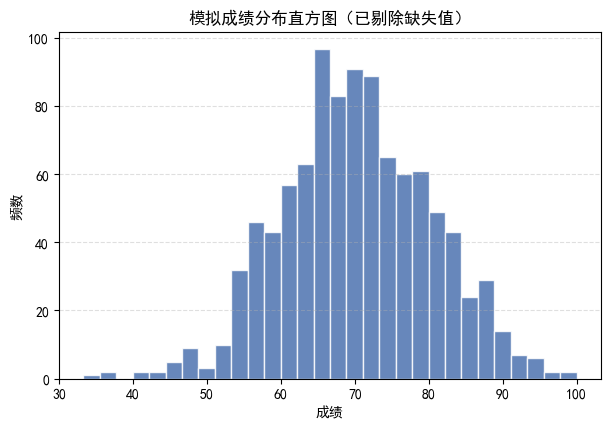

In [18]:
# 有效成绩：剔除实验2 中被设为 nan 的三处
valid_scores = scores_with_nan[~np.isnan(scores_with_nan)]
print(f"有效成绩个数：{valid_scores.size}")
print(f"缺失值个数  ：{scores_with_nan.size - valid_scores.size}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(valid_scores, bins=30, color="#4C72B0", edgecolor="white", alpha=0.85)
ax.set_title("模拟成绩分布直方图（已剔除缺失值）")
ax.set_xlabel("成绩")
ax.set_ylabel("频数")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

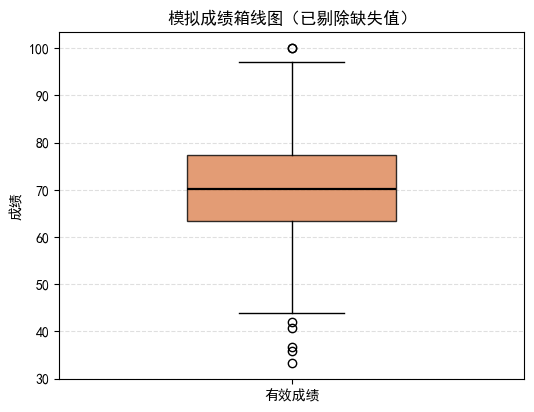

In [19]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.boxplot(
    valid_scores,
    patch_artist=True,
    widths=0.45,
    boxprops=dict(facecolor="#DD8452", alpha=0.8),
    medianprops=dict(color="black", linewidth=1.6),
)
ax.set_title("模拟成绩箱线图（已剔除缺失值）")
ax.set_ylabel("成绩")
ax.set_xticks([1])
ax.set_xticklabels(["有效成绩"])
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

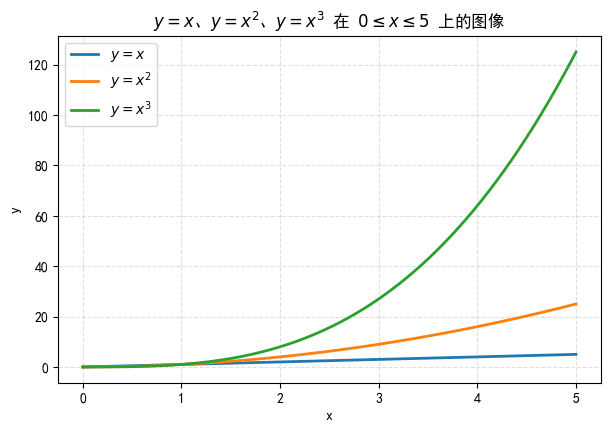

In [20]:
x = np.linspace(0, 5, 200)

fig, ax = plt.subplots(figsize=(7, 4.5))
# 用 mathtext 写公式：SimHei 字体本身不含上标 ²、³，直接写会缺字形
ax.plot(x, x,     linewidth=2, label=r"$y = x$")
ax.plot(x, x**2,  linewidth=2, label=r"$y = x^2$")
ax.plot(x, x**3,  linewidth=2, label=r"$y = x^3$")
ax.set_title(r"$y=x$、$y=x^2$、$y=x^3$ 在 $0 \leq x \leq 5$ 上的图像")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(linestyle="--", alpha=0.4)
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

### 1. 创建 DataFrame 并计算总分、平均分

用题给字典创建 `DataFrame`，**以 `Name` 作为行索引**（`set_index("Name")`），再新增 `Total`（三科总分）与 `Average`（三科平均分）两列。

输出行索引、列名、前 3 行和基本统计信息。

In [21]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引 :", list(df.index))
print("列名   :", list(df.columns))
print()
print("前 3 行：")
print(df.head(3))
print()
print("基本统计信息：")
print(df.describe())

行索引 : ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名   : ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


### 2. `loc` 与 `iloc`，以及条件筛选

- `loc` 按**标签**索引：`df.loc["Carol"]`；
- `iloc` 按**整数位置**索引：Carol 是第 3 行，位置为 2，即 `df.iloc[2]`。

筛选平均分不低于 80 的学生。

In [22]:
print("loc['Carol']（按标签）：")
print(df.loc["Carol"])
print()
print("iloc[2]（按位置，Carol 在第 3 行）：")
print(df.iloc[2])
print()
print("两者是否一致 :", df.loc["Carol"].equals(df.iloc[2]))
print()

print("平均分不低于 80 的学生：")
print(df[df["Average"] >= 80][["Group", "Math", "English", "Python", "Total", "Average"]])

loc['Carol']（按标签）：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc[2]（按位置，Carol 在第 3 行）：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

两者是否一致 : True

平均分不低于 80 的学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


### 3. `mean(axis=0)` 与 `mean(axis=1)`

- `axis=0`：沿行方向压缩，得到**每一列**的均值；
- `axis=1`：沿列方向压缩，得到**每一行**的均值。

> **注意**：必须先取出三科成绩列再求行均值。如果直接对包含 `Total` 的整个 `df` 调 `mean(axis=1)`，`Total` 是总分、量级远大于单科成绩，会把行均值拉偏。

In [23]:
subjects = ["Math", "English", "Python"]

col_mean = df[subjects].mean(axis=0)
row_mean = df[subjects].mean(axis=1)

print("mean(axis=0) —— 每科的列均值：")
print(col_mean)
print()

print("mean(axis=1) —— 每名学生的行均值：")
print(row_mean)
print()

print("行均值与 Average 列完全一致 :",
      np.allclose(row_mean.values, df["Average"].values))
print()
print("对照：若误把 Total 也算进行均值，结果会变成：")
print(df.mean(axis=1, numeric_only=True))

mean(axis=0) —— 每科的列均值：
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

mean(axis=1) —— 每名学生的行均值：
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64

行均值与 Average 列完全一致 : True

对照：若误把 Total 也算进行均值，结果会变成：
Name
Alice    127.400000
Bob      102.666667
Carol    123.666667
David     97.066667
Eva      119.933333
Frank    113.400000
dtype: float64


### 4. `apply()`、`agg()` 与 `rank()`

- `apply(max, axis=1)`：对每一行应用 `max`，得到每名学生三科中的最高分；
- `agg(["min", "mean", "max"])`：一次调用得到每科的最小值、均值、最大值；
- `rank(ascending=False)`：对某一列排名，分数高的名次靠前。

In [24]:
df["Best"] = df[subjects].apply(max, axis=1)
print("每名学生的三科最高分：")
print(df[["Math", "English", "Python", "Best"]])
print()

subject_summary = df[subjects].agg(["min", "mean", "max"])
print("每科最小值 / 均值 / 最大值：")
print(subject_summary)
print()

df["Math_rank"] = df["Math"].rank(ascending=False, method="min").astype(int)
print("按 Math 从高到低排名（method='min'，并列取最小名次）：")
print(df[["Math", "Math_rank"]].sort_values("Math", ascending=False))

每名学生的三科最高分：
       Math  English  Python  Best
Name                              
Alice    88       90      95    95
Bob      72       68      80    80
Carol    91       85      89    91
David    65       73      70    73
Eva      79       92      86    92
Frank    84       77      82    84

每科最小值 / 均值 / 最大值：
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

按 Math 从高到低排名（method='min'，并列取最小名次）：
       Math  Math_rank
Name                  
Carol    91          1
Alice    88          2
Frank    84          3
Eva      79          4
Bob      72          5
David    65          6


### 5. 按 `Group` 分组统计，并用 `transform('mean')` 增加组均值列

- `groupby("Group").size()`：每组人数；
- `groupby("Group")[subjects].mean()`：每组三科平均分；
- `transform('mean')` **保留原表的行数**，把每行所在组的均值填回该行，因此可以直接赋值为新列。这一点与 `groupby(...).mean()` 不同——后者会把结果压缩成每组一行。

In [25]:
group_count = df.groupby("Group").size().rename("人数")
group_mean = df.groupby("Group")[subjects].mean()

print("每组人数：")
print(group_count)
print()
print("每组三科平均分：")
print(group_mean)
print()

df["GroupPythonMean"] = df.groupby("Group")["Python"].transform("mean")
print("为每行增加其所在组的 Python 平均分：")
print(df[["Group", "Python", "GroupPythonMean"]])

每组人数：
Group
A    3
B    3
Name: 人数, dtype: int64

每组三科平均分：
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

为每行增加其所在组的 Python 平均分：
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


### 6. `filter()` 保留 Python 平均分不低于 80 的组

`filter()` 的作用对象是**组**：函数返回 `True` 的组整体保留，返回 `False` 的组整组删除。

先看各组的 Python 平均分再筛选，才能解释结果。

In [26]:
python_mean_by_group = df.groupby("Group")["Python"].mean()
print("各组 Python 平均分：")
print(python_mean_by_group)
print()

kept = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)

print("保留的组  :", sorted(kept["Group"].unique()))
print("保留的学生:", list(kept.index))
print()
print(kept[["Group", "Math", "English", "Python", "Average", "GroupPythonMean"]])
print()
print("说明：" + "、".join(f"{g} 组 {v:.2f}" for g, v in python_mean_by_group.items())
      + "，均不低于 80，")
print(f"      所以两组都被保留，{len(kept)} 名学生全部留下。")

各组 Python 平均分：
Group
A    87.000000
B    80.333333
Name: Python, dtype: float64

保留的组  : ['A', 'B']
保留的学生: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']

      Group  Math  English  Python    Average  GroupPythonMean
Name                                                          
Alice     A    88       90      95  91.000000        87.000000
Bob       A    72       68      80  73.333333        87.000000
Carol     B    91       85      89  88.333333        80.333333
David     B    65       73      70  69.333333        80.333333
Eva       A    79       92      86  85.666667        87.000000
Frank     B    84       77      82  81.000000        80.333333

说明：A 组 87.00、B 组 80.33，均不低于 80，
      所以两组都被保留，6 名学生全部留下。


### 7. 协方差矩阵与皮尔森相关系数矩阵

- `df.cov()`：协方差矩阵，元素 $\mathrm{Cov}(X, Y)$ 反映**变化方向**；
- `df.corr()`：皮尔森相关系数矩阵，$r = \dfrac{\mathrm{Cov}(X,Y)}{\sigma_X \sigma_Y} \in [-1, 1]$，反映**线性相关的强弱与方向**。

**以 Math 与 English 为例**（具体数值见上一单元格输出）：

- 协方差为**正**，说明两科成绩同向变化——数学高于平均水平的同学，英语往往也高于平均水平；
- 相关系数约为 $0.65$，属于**中等偏强**的正线性相关（$|r|$ 越接近 1 越强）；
- 相关系数比协方差更容易解读：它消除了各科分数尺度不同的影响，是无量纲的；协方差的大小则依赖单位，不能直接跨科目比较。

In [27]:
cov_mx = df[subjects].cov()
corr_mx = df[subjects].corr()

print("协方差矩阵：")
print(cov_mx.round(3))
print()
print("皮尔森相关系数矩阵：")
print(corr_mx.round(3))
print()

r_math_eng = corr_mx.loc["Math", "English"]
print(f"Math 与 English 的协方差 = {cov_mx.loc['Math', 'English']:.3f}")
print(f"Math 与 English 的相关系数 = {r_math_eng:.3f}")
print(f"解释：协方差为正，两科同向变化；|r| = {abs(r_math_eng):.3f}，属于中等偏强的正线性相关。")

协方差矩阵：
           Math  English  Python
Math     98.167   62.567  74.933
English  62.567   93.367  62.533
Python   74.933   62.533  73.067

皮尔森相关系数矩阵：
          Math  English  Python
Math     1.000    0.654   0.885
English  0.654    1.000   0.757
Python   0.885    0.757   1.000

Math 与 English 的协方差 = 62.567
Math 与 English 的相关系数 = 0.654
解释：协方差为正，两科同向变化；|r| = 0.654，属于中等偏强的正线性相关。


### 补充：内存中的 CSV 读写

本节标题包含"内存中的 CSV 读写"，但没有给出单独编号的任务。这里用 `io.StringIO` 把实验2.5 的 `score_table` 写成 CSV **文本**再读回来，验证往返一致——全程不落盘。

`StringIO` 把字符串当作文件对象使用，接口与 `open()` 得到的文件相同，因此同一个 `to_csv` / `read_csv` 流程可以直接复用。

需要注意：CSV 是**文本**格式，浮点数写出去再读回来时，受十进制位数与解析算法的限制，可能出现 $10^{-14}$ 量级的误差。所以这里用 `np.allclose()` 按容差比较，而不是要求逐位相等。

In [28]:
import io

buffer = io.StringIO()
score_table.to_csv(buffer, index=False)
csv_text = buffer.getvalue()

print("写入内存的 CSV 前 4 行：")
print("\n".join(csv_text.splitlines()[:4]))
print()
print(f"CSV 文本长度：{len(csv_text)} 字符（没有任何文件被创建到磁盘）")
print()

restored = pd.read_csv(io.StringIO(csv_text))

mask = ~np.isnan(score_table["成绩"].to_numpy())
max_diff = float(np.max(np.abs(restored["成绩"].to_numpy()[mask]
                               - score_table["成绩"].to_numpy()[mask])))

print("读回后的形状       :", restored.shape)
print("与原表格形状一致   :", restored.shape == score_table.shape)
print("缺失值个数保持不变 :", int(restored["成绩"].isna().sum()),
      "->", int(score_table["成绩"].isna().sum()))
print(f"数值最大绝对误差   : {max_diff:.3e}")
print("在 1e-12 容差内一致:", np.allclose(restored["成绩"], score_table["成绩"],
                                        rtol=0, atol=1e-12, equal_nan=True))
print()
print(restored.head(8))

写入内存的 CSV 前 4 行：
序号,成绩
1,86.68047321311954
2,77.37347726754895
3,67.9846224262833

CSV 文本长度：22769 字符（没有任何文件被创建到磁盘）

读回后的形状       : (1000, 2)
与原表格形状一致   : True
缺失值个数保持不变 : 3 -> 3
数值最大绝对误差   : 1.421e-14
在 1e-12 容差内一致: True

   序号         成绩
0   1  86.680473
1   2  77.373477
2   3  67.984622
3   4  68.490881
4   5  79.160518
5   6  81.603296
6   7  43.800380
7   8  56.747054


## 实验总结

| 实验 | 主要内容 | 关键结论 |
|---|---|---|
| 1 | ndarray 的类型、形状与索引 | `reshape` 要求元素总数不变；布尔条件必须加括号 |
| 2 | 随机抽样与缺失值 | `permutation` 返回副本，`shuffle` 原地修改；`nan` 会污染普通统计量，需用 `nanmean` |
| 3 | SciPy 求解与可视化 | 线性方程组解为 $(2, 3)$；$x^2-2=0$ 的正负根依初值而定；$f(x)=x+\frac{2}{x+2}$ 的极小点为 $-2+\sqrt{2}$；两组样本的 t 检验拒绝原假设 |
| 4 | pandas 数据处理 | 行索引取姓名；`axis=0/1` 对应列/行聚合；`transform` 保留行数，`filter` 作用于组 |

所有随机实验均固定种子 `2024`；图表直接在 Notebook 中显示，未保存任何文件。